In [1]:
import pandas as pd
import numpy as np
import scipy
import matplotlib
import sklearn

print("pandas", pd.__version__)
print("numpy", np.__version__)
print("scipy", scipy.__version__)
print("all good")

pandas 2.3.3
numpy 2.0.2
scipy 1.13.1
all good


In [2]:
import glob
files = sorted(glob.glob("data/*/*.txt"))
print(len(files), "files found")
print(files[:3])

72 files found
['data/01/1_raw_data_13-12_22.03.16.txt', 'data/01/2_raw_data_13-13_22.03.16.txt', 'data/02/1_raw_data_14-19_22.03.16.txt']


In [3]:
import pandas as pd

d = pd.read_csv(files[0], sep="\t")
print(d.shape)
print(d.columns.tolist())
print(d.head())
print()
print("Missing values per column:")
print(d.isna().sum())
print()
print("Rows per gesture class:")
print(d["class"].value_counts().sort_index())

(63196, 10)
['time', 'channel1', 'channel2', 'channel3', 'channel4', 'channel5', 'channel6', 'channel7', 'channel8', 'class']
   time  channel1  channel2  channel3  channel4  channel5  channel6  channel7  \
0     1   0.00001  -0.00002  -0.00001  -0.00003   0.00000  -0.00001   0.00000   
1     5   0.00001  -0.00002  -0.00001  -0.00003   0.00000  -0.00001   0.00000   
2     6  -0.00001   0.00001   0.00002   0.00000   0.00001  -0.00002  -0.00001   
3     7  -0.00001   0.00001   0.00002   0.00000   0.00001  -0.00002  -0.00001   
4     8  -0.00001   0.00001   0.00002   0.00000   0.00001  -0.00002  -0.00001   

   channel8  class  
0  -0.00001      0  
1  -0.00001      0  
2   0.00001      0  
3   0.00001      0  
4   0.00001      0  

Missing values per column:
time        0
channel1    0
channel2    0
channel3    0
channel4    0
channel5    0
channel6    0
channel7    0
channel8    0
class       0
dtype: int64

Rows per gesture class:
class
0    41272
1     3780
2     3525
3     3816
4    

In [4]:
fs = 1000 / d["time"].diff().median()
print("Sampling rate (Hz):", fs)

Sampling rate (Hz): 1000.0


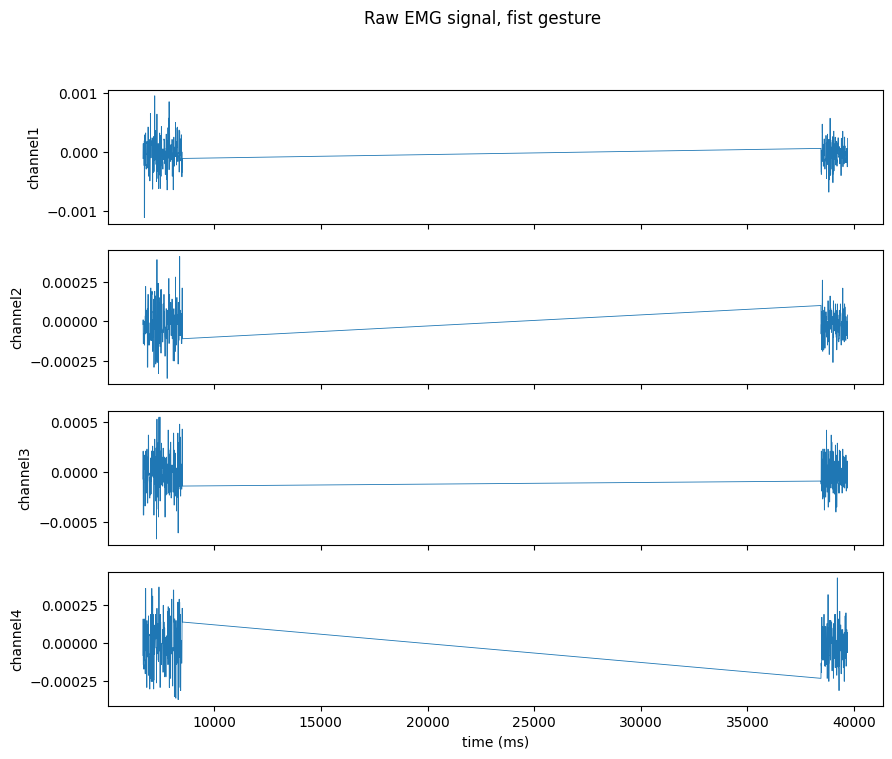

In [6]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

channels = [f"channel{i}" for i in range(1, 9)]

# 3 seconds of the fist gesture (class 2)
seg = d[d["class"] == 2].iloc[:3000]

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, ch in zip(axes, channels[:4]):
    ax.plot(seg["time"], seg[ch], linewidth=0.6)
    ax.set_ylabel(ch)
axes[-1].set_xlabel("time (ms)")
plt.suptitle("Raw EMG signal, fist gesture")
plt.savefig("figures/raw_signal.png", dpi=150, bbox_inches="tight")
plt.show()

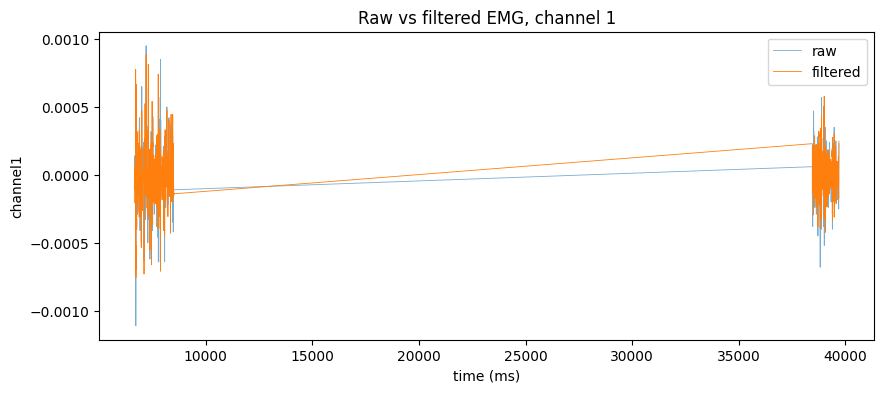

In [7]:
from scipy.signal import butter, sosfiltfilt

def bandpass(x, fs, low=20, high=450, order=4):
    sos = butter(order, [low, high], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

# filter all 8 channels of the whole recording
filtered = d.copy()
for ch in channels:
    filtered[ch] = bandpass(d[ch].values, fs)

# compare raw vs filtered on one channel (same 3 seconds as before)
seg_raw = d[d["class"] == 2].iloc[:3000]
seg_filt = filtered.loc[seg_raw.index]

plt.figure(figsize=(10, 4))
plt.plot(seg_raw["time"], seg_raw["channel1"], label="raw", alpha=0.6, linewidth=0.6)
plt.plot(seg_filt["time"], seg_filt["channel1"], label="filtered", linewidth=0.6)
plt.xlabel("time (ms)")
plt.ylabel("channel1")
plt.title("Raw vs filtered EMG, channel 1")
plt.legend()
plt.savefig("figures/filter_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
win_ms = 200
overlap = 0.5

win = int(fs * win_ms / 1000)      # samples per window (200)
step = int(win * (1 - overlap))    # how far we slide each time (100)
print("Window size:", win, "samples | Step:", step, "samples")

windows = []
for start in range(0, len(filtered) - win, step):
    w = filtered.iloc[start:start + win]
    labels = w["class"].unique()

    # keep only windows with one gesture, and only gestures 1 to 6
    if len(labels) != 1 or labels[0] not in range(1, 7):
        continue

    windows.append((start, int(labels[0])))

win_df = pd.DataFrame(windows, columns=["start", "gesture"])
print("Number of windows:", len(win_df))
print(win_df["gesture"].value_counts().sort_index())

Window size: 200 samples | Step: 100 samples
Number of windows: 197
gesture
1    34
2    31
3    34
4    31
5    33
6    34
Name: count, dtype: int64


In [9]:
def window_features(w):
    row = {}
    for ch in channels:
        x = w[ch].values
        row[f"{ch}_rms"] = np.sqrt(np.mean(x ** 2))
        row[f"{ch}_mav"] = np.mean(np.abs(x))
        row[f"{ch}_wl"] = np.sum(np.abs(np.diff(x)))
    return row

rows = []
for start, gesture in windows:
    w = filtered.iloc[start:start + win]
    row = window_features(w)
    row["gesture"] = gesture
    rows.append(row)

feat = pd.DataFrame(rows)
feat["subject"] = "01"          # we will fill real subject IDs when we loop over many subjects
feat.to_csv("features.csv", index=False)

print(feat.shape)
print(feat.head())


(197, 26)
   channel1_rms  channel1_mav  channel1_wl  channel2_rms  channel2_mav  \
0      0.000007      0.000005     0.000428      0.000016      0.000013   
1      0.000007      0.000006     0.000444      0.000016      0.000013   
2      0.000008      0.000007     0.000471      0.000012      0.000010   
3      0.000008      0.000006     0.000460      0.000014      0.000012   
4      0.000006      0.000005     0.000357      0.000016      0.000013   

   channel2_wl  channel3_rms  channel3_mav  channel3_wl  channel4_rms  ...  \
0     0.000904      0.000017      0.000014     0.001057      0.000013  ...   
1     0.000934      0.000021      0.000016     0.001154      0.000010  ...   
2     0.000745      0.000023      0.000019     0.001304      0.000011  ...   
3     0.000687      0.000023      0.000021     0.001182      0.000013  ...   
4     0.000839      0.000020      0.000017     0.001040      0.000011  ...   

   channel6_mav  channel6_wl  channel7_rms  channel7_mav  channel7_wl  \
0  